# Chart 1: Waiting vs Cost in Ireland

Team: The Foreigners. Chart 1 of the final visualization package (by Daniel).

The chart answers question 1: has waiting replaced cost as the main reason people in Ireland go without medical care? 

It uses the prepared table `unmet_need_by_reason` from the data audit (`Data_Audit.ipynb`), which holds the share of people aged 16 and over who needed a medical examination and did not get one, by main reason.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

PREPARED = Path("../data/prepared") # the notebook sits one folder down
FIGURES = Path("../figures") # the team's shared figures folder
FIGURES.mkdir(exist_ok=True)

ORANGE = "#eb6834" # waiting
BLUE = "#2a78d6" # cost
GREY = "#898781" # EU average and background

unmet = pd.read_csv(PREPARED / "unmet_need_by_reason_v1_2026-11-11.csv")
unmet.head()

,area,area_code,group,year,reason,pct,flag,is_break
0,Austria,AT,Other EU country,2016,Too expensive,0.2,NaN,False
1,Austria,AT,Other EU country,2017,Too expensive,0.2,NaN,False
2,Austria,AT,Other EU country,2018,Too expensive,0.1,NaN,False
3,Austria,AT,Other EU country,2019,Too expensive,0.2,NaN,False
4,Austria,AT,Other EU country,2020,Too expensive,0.1,NaN,False


## 1.1 Keep the Irish rows

One row per year, with the two reasons as columns.

In [2]:
ireland = unmet[unmet["group"] == "Ireland"]
lines = ireland.pivot(index="year", columns="reason", values="pct")
lines

reason,Too expensive,Waiting list
year,,
2016,1.5,1.0
2017,1.3,1.5
2018,0.9,1.0
2019,0.9,1.0
2020,0.6,1.2
2021,0.1,2.0
2022,0.4,2.3
2023,0.6,2.1
2024,0.2,2.7


## 1.2 Check the numbers

These are the numbers from the Chart Guide. If any of them is wrong, the cell stops with an error.

In [3]:
wait = lines["Waiting list"]
cost = lines["Too expensive"]

assert (wait[2016], cost[2016]) == (1.0, 1.5)
assert (wait[2025], cost[2025]) == (2.1, 0.6)
assert wait.max() == 2.7 and wait.idxmax() == 2024 # highest waiting value
assert (wait.loc[2017:] > cost.loc[2017:]).all() # waiting above cost every year from 2017

print("Gap (waiting minus cost), in points:")
(wait - cost).round(1)

Gap (waiting minus cost), in points:


year
2016   -0.5
2017    0.2
2018    0.1
2019    0.1
2020    0.6
2021    1.9
2022    1.9
2023    1.5
2024    2.5
2025    1.5
dtype: float64

All checks pass. Cost was the bigger reason only in 2016. From 2017 waiting is above cost in every year, although the gap is small in 2018 and 2019 (0.1 points), and it widens from 2021.

## 1.3 Find the break years

Eurostat flags a break in Ireland's series in some years. These are taken from the `is_break` column rather than typed in.

In [4]:
break_years = sorted(ireland.loc[ireland["is_break"], "year"].unique())
break_years

[np.int64(2019), np.int64(2020)]

## Chart 1: waiting vs cost

**Why this chart type.** The data is two series (waiting and cost) over ten years, so a line chart shows how each one changes and the point where waiting overtakes cost. Grouped bars would split each year into two separate bars and hide that crossover, and a pie chart has no time axis. The y-axis starts at zero so that the size of each line is shown honestly, since the values are all small (0.1% to 2.7%).

**Data, marks and channels.**

- Data: year is temporal (T), the reason is a category with two values (C: waiting list, too expensive), and the share is quantitative (Q, % of people aged 16+). So the chart shows T and C against Q.
- Marks: lines, which connect the years so the change over time reads as one movement, and points, one for each survey year, because there are only ten real values.
- Channels: vertical position shows the share, horizontal position shows the year, colour hue shows the reason (orange waiting, blue cost), and the point fill shows the break years (hollow). Position is the most accurate channel for comparing values, so it carries the numbers. Hue only separates two categories, so it does not suggest any order.

**Other options considered.** A slope chart of only 2016 and 2025 would show the swap, but it would hide the 2017 crossover and the 2024 peak. Grouped bars and a pie chart are rejected for the reasons above.

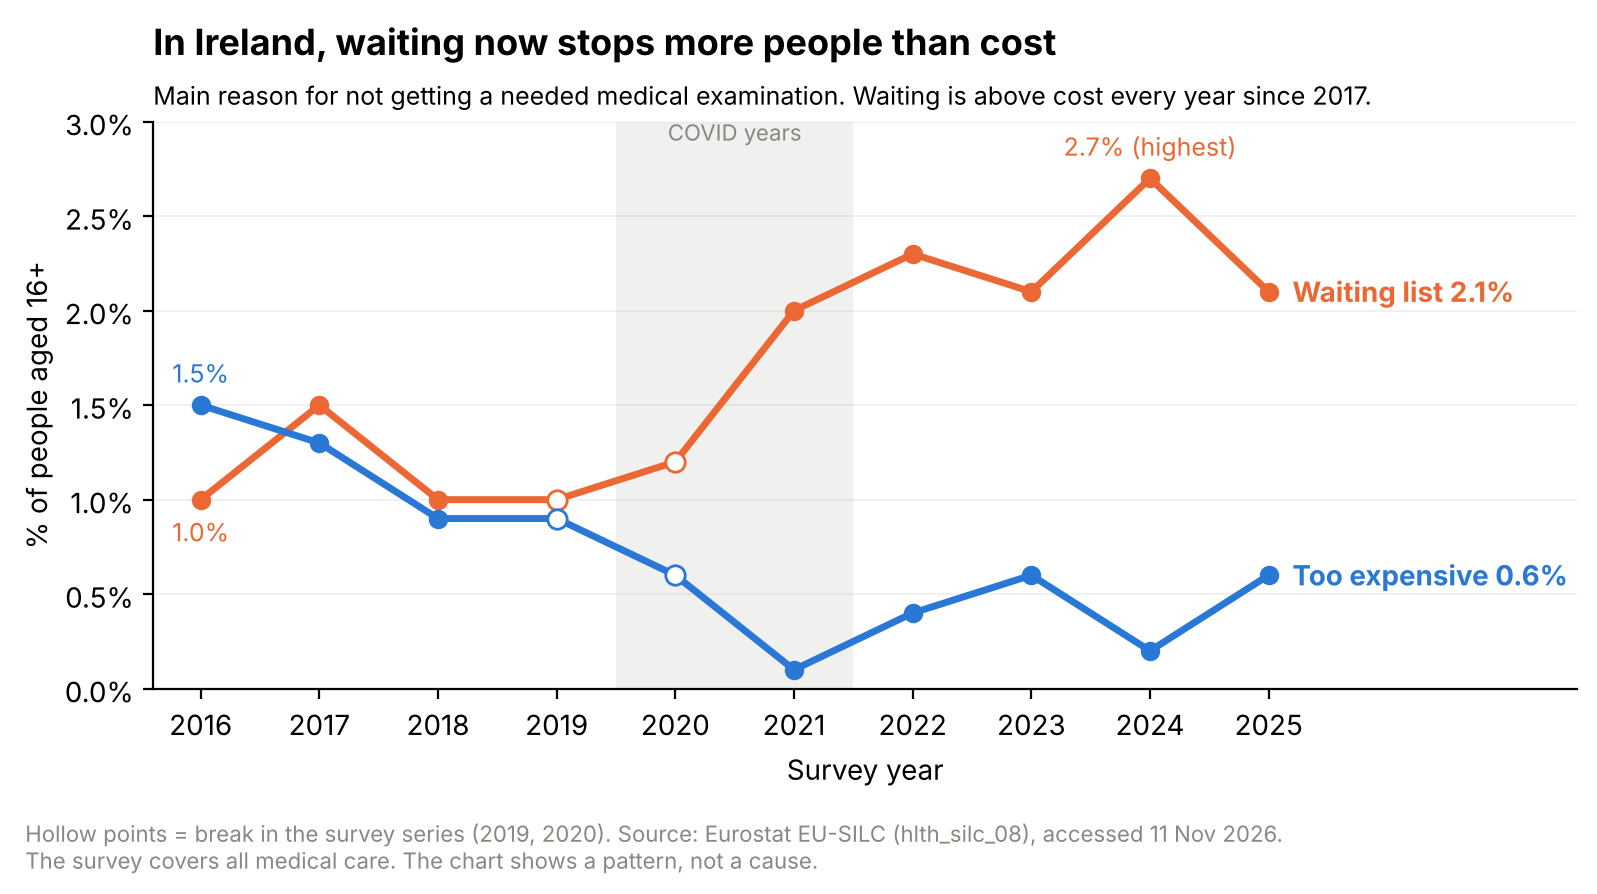

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# the two lines, with a marker for every year
ax.plot(wait.index, wait, color=ORANGE, linewidth=2.5, marker="o")
ax.plot(cost.index, cost, color=BLUE, linewidth=2.5, marker="o")

# break years: hollow markers (white fill, coloured edge) on top
ax.plot(break_years, wait[break_years], "o", color=ORANGE, markerfacecolor="white", markersize=7)
ax.plot(break_years, cost[break_years], "o", color=BLUE, markerfacecolor="white", markersize=7)

# COVID years, as a light grey band behind the lines
ax.axvspan(2019.5, 2021.5, color=GREY, alpha=0.12, linewidth=0)
ax.text(2020.5, 2.9, "COVID years", ha="center", fontsize=8, color=GREY)

# labels at the end of each line, so no legend is needed
ax.text(2025.2, wait[2025], f"Waiting list {wait[2025]}%", color=ORANGE, va="center", fontweight="bold")
ax.text(2025.2, cost[2025], f"Too expensive {cost[2025]}%", color=BLUE, va="center", fontweight="bold")

# the first values and the highest point
ax.text(2016, wait[2016] - 0.22, f"{wait[2016]}%", color=ORANGE, ha="center", fontsize=9)
ax.text(2016, cost[2016] + 0.12, f"{cost[2016]}%", color=BLUE, ha="center", fontsize=9)
ax.text(2024, wait[2024] + 0.12, f"{wait[2024]}% (highest)", color=ORANGE, ha="center", fontsize=9)

# axes
ax.set_ylim(0, 3)
ax.set_xlim(2015.6, 2027.6)
ax.set_xticks(range(2016, 2026))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=1))
ax.set_xlabel("Survey year")
ax.set_ylabel("% of people aged 16+")
ax.grid(axis="y", color="#efefef", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

# title (the finding), subtitle, and the note under the chart
ax.set_title("In Ireland, waiting now stops more people than cost", loc="left", fontsize=13, fontweight="bold", pad=24)
ax.text(0, 1.03, "Main reason for not getting a needed medical examination. Waiting is above cost every year since 2017.",
        transform=ax.transAxes, fontsize=9)
fig.text(0.01, 0.02,
         "Hollow points = break in the survey series (2019, 2020). Source: Eurostat EU-SILC (hlth_silc_08), accessed 11 Nov 2026.\n"
         "The survey covers all medical care. The chart shows a pattern, not a cause.",
         fontsize=8, color=GREY)

fig.subplots_adjust(top=0.85, bottom=0.22, left=0.09, right=0.98)
fig.savefig(FIGURES / "chart1_waiting_vs_cost.png", dpi=200)
plt.show()

**Note:** In 2016 cost was the bigger reason for going without care in Ireland (1.5% against 1.0% for waiting). From 2017 waiting is above cost in every year. The two lines stay close until 2020, then move apart: waiting jumps from 1.2% in 2020 to 2.0% in 2021, reaches its highest value of 2.7% in 2024, and is 2.1% in 2025. Cost falls to 0.1% in 2021 and is 0.6% in 2025. By 2025 waiting is about three and a half times cost.

- The values are small, so a change of 0.1 or 0.2 points can be survey noise. The message rests on the direction over several years, not on one year.
- 2019 and 2020 are break years in the Eurostat series, so they are not fully comparable with the other years. The hollow points mark them.
- The big change happens across the COVID years, so COVID may be part of it, but the chart cannot show why the lines moved.
- The survey covers all medical care, not only hospital care. The chart shows a pattern, not a cause.

## Decisions

What was suggested (by the Chart Guide or by AI), what I decided, and why. The significant AI suggestions are also in the team's AI Decision Log (rows 21 to 23).

| Choice | Suggested | My decision and why |
| --- | --- | --- |
| Chart type | Line chart (guide); AI drafted it as a line chart | Kept. Two series over ten years, and the story is where waiting overtakes cost (2017) and the gap that opens from 2021. Grouped bars would give 20 separate bars and hide the crossover, a slope chart (2016 vs 2025) would hide the 2017 crossover and the 2024 peak, and a pie chart has no time axis. |
| Title | "In Ireland, waiting now stops more people than cost" (guide) | Kept. The checks show it is true in every year from 2017 to 2025. "Now" matters, because in 2016 cost was higher (1.5% against 1.0%). Not made stronger (for example "far more"), because the gap is only 0.1 points in 2018 and 2019. |
| Subtitle | AI added one line under the title | Kept. It says what the measure is and that waiting is above cost every year since 2017, so the title's claim is backed on the chart itself. |
| Y-axis | Start at 0, up to 3% | Kept. The values are small (0.1% to 2.7%), so a cut axis would make a 0.1 point change look dramatic. The 0 to 3% range is the same as Jenny's Chart 2, so the two charts can be compared directly. |
| Markers | A marker for every year | Kept. There are only ten yearly survey values, and the markers show that the line joins separate points, not a continuous measure. |
| Break years | Hollow markers for 2019 and 2020, found from `is_break` | Kept. The years stay in the chart but are flagged as not fully comparable. Reading them from `is_break` means they come from the data, not typed by hand. |
| COVID years | Light grey band over 2020 and 2021 (AI added it, from the style rules) | Kept. The jump in waiting from 1.2% to 2.0% falls inside it, so the reader should see it. The note still says the chart does not show a cause. The other charts should mark COVID the same way. |
| Labels | Direct labels at the line ends, no legend | Kept. With only two lines, a label next to each line is quicker to read than a legend. |
| Values shown | Only the 2016 values, the 2024 peak and the 2025 values | Kept. These carry the story (where it started, the highest point, where it is now). Labelling all 20 points would clutter the chart. |
| Colours | Waiting orange, cost blue (team style rule) | Kept, so the colours mean the same thing in every chart of the set. |
| Note under the chart | Source, access date, break years, survey covers all care, pattern not cause | Kept, and I reworded the break-year part ("Hollow points = break in the survey series"). The note covers the limits a reader needs without a separate legend. |
| Number checks | The guide's numbers written as `assert` lines | Kept. If the data or the code changes, the notebook stops instead of drawing a wrong chart. |
| Size and file | 8 x 4.5 inches, 200 dpi, saved to `figures/chart1_waiting_vs_cost.png` (style rules) | Kept, so all five charts match in the final package. |
| X-axis label | "Survey year" | Added, so both axes are labelled as Submission 6 asks. EU-SILC values are by survey year. |
| Marks and channels | Lines and points; position, hue and fill (written out above the chart) | Kept. Position carries the values because it is read most accurately; hue only separates the two reasons. |
| Left out | The EU average (Chart 2) and the NTPF waiting list (Charts 3 and 4) | Kept out, so this chart answers question 1 only. The NTPF table is not loaded at all, because this notebook does not use it. |